In [ ]:
import logging
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.metrics.pairwise import euclidean_distances, rbf_kernel
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from split_first import check_same_test_set, load_split

from _utilities.stupidlogger import StupidLogGenerator

ROOT_DIR = os.environ["VIRTUAL_ENV"][:-5]
sys.path.append(ROOT_DIR)

In [35]:
PATH_REAL_DATA = "data/preprocessed_real_data.csv"
PATH_SYNTHETIC_DATA = "data/synthetic/"
PATH_FOLDER_MODELS = "models/"

In [3]:
logger = StupidLogGenerator.initLogger()

In [4]:
# Real Dataset
real_df = pd.read_csv(PATH_REAL_DATA)

# Target Column
target_feature = "is_recid"

# Sensitive Column
sensitive_feature = "sex"

# Synthetic Datasets
synthetic_datasets = {}

# Leaky Columns
LEAK_COLS = ["r_charge_degree", "r_charge_desc", "two_year_recid"]

X_real = real_df.drop(columns=[target_feature] + LEAK_COLS)
CATEGORICAL_COLS = X_real.select_dtypes(include=["object"]).columns.tolist()
NUMERICAL_COLS = X_real.select_dtypes(exclude=["object"]).columns.tolist()
FEATURE_ORDER = X_real.columns.tolist()


In [ ]:
# Load synthetic datasets
dir_list = os.listdir(PATH_SYNTHETIC_DATA)

# A synthetic file older than the split was generated before it, by a model that saw the test set
split_time = os.path.getmtime("data/split/real_train.csv")

for file_name in dir_list:
    if not file_name.endswith("_synthetic.csv"):
        continue
    if os.path.getmtime(PATH_SYNTHETIC_DATA + file_name) < split_time:
        logger.warning(f"Skipping {file_name}: created before the train/test split")
        continue
    model_name = file_name.replace("_synthetic.csv", "").replace("lambda_", "")
    synthetic_datasets[model_name] = pd.read_csv(PATH_SYNTHETIC_DATA + file_name)

### Check synthetic data against the real schema
TabFairGAN was trained with `sex` and `is_recid` cast to strings, and its library may reorder or drop columns.
A missing column would silently become NaN inside the classifier, so each dataset is checked before use.


In [ ]:
for model_name, df in synthetic_datasets.items():
    missing = set(real_df.columns) - set(df.columns)
    extra = set(df.columns) - set(real_df.columns)
    if missing or extra:
        logger.warning(f"{model_name}: missing {missing}, extra {extra}")

    # Same column order as the real data; extra columns are dropped
    df = df.reindex(columns=real_df.columns)

    # Target back to 0/1 integers, whatever type the generator wrote it as
    df[target_feature] = pd.to_numeric(df[target_feature], errors="coerce")
    bad = ~df[target_feature].isin([0, 1])
    if bad.any():
        logger.warning(f"{model_name}: dropping {bad.sum()} rows with invalid {target_feature}")
        df = df[~bad]
    df[target_feature] = df[target_feature].astype(int)

    synthetic_datasets[model_name] = df

In [6]:
leaks = pd.DataFrame(columns=["column", "percent", "leak_count", "total_count"])
for col in CATEGORICAL_COLS + NUMERICAL_COLS:
    t_df = real_df.groupby(col)[target_feature].mean().to_frame().reset_index()
    n = t_df.shape[0]
    leak_count = t_df["is_recid"].value_counts().get(0, 0) + t_df[
        "is_recid"
    ].value_counts().get(1, 0)
    percent = leak_count / n * 100
    leaks.loc[len(leaks)] = [col, round(percent, 0), leak_count, n]

display(leaks)

,column,percent,leak_count,total_count
0,sex,0.0,0,2
1,age_cat,0.0,0,3
2,race,0.0,0,3
3,c_charge_degree,0.0,0,2
4,c_charge_desc,57.0,248,437
5,age,18.0,12,65
6,juv_fel_count,55.0,6,11
7,juv_misd_count,30.0,3,10
8,juv_other_count,30.0,3,10
9,priors_count,19.0,7,37


## Downstream Classifier

### Preprocessing

In [ ]:
# The split is made once in Notebook_Models.ipynb, before any generator is trained
real_train_df, real_test_df = load_split()

assert list(real_train_df.columns) == list(real_df.columns), "split columns differ from preprocessed data"
assert len(real_train_df) + len(real_test_df) == len(real_df), "split row count differs from preprocessed data"

# Confirms the test set is the same rows as before, so the Real baseline is unchanged
_, old_test_df = train_test_split(real_df, test_size=0.2, random_state=42)
print("Test set identical to previous split:", check_same_test_set(old_test_df.index, real_test_df))


def build_pipeline(categorical_cols: list[str], numerical_cols: list[str]) -> Pipeline:
    """Builds a preprocessing + Logistic Regression pipeline"""

    preprocessor = ColumnTransformer(
        transformers=[
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
            ("num", "passthrough", numerical_cols),
        ]
    )

    pipeline = Pipeline(
        [
            ("preprocessor", preprocessor),
            ("classifier", LogisticRegression(max_iter=1000)),
        ]
    )

    return pipeline

### Train the classifier

In [8]:
def train_pipeline(
    train_df: pd.DataFrame,
    target_col: str,
    categorical_cols: list[str],
    numeric_cols: list[str],
    feature_order: list[str],
) -> Pipeline:
    """Trains a pipeline on a given dataset."""

    X_train = train_df.drop(columns=[target_col])
    y_train = train_df[target_col]

    X_train = X_train.reindex(columns=feature_order)

    pipeline = build_pipeline(categorical_cols, numeric_cols)
    pipeline.fit(X_train, y_train)

    return pipeline

### Run the training on the real dataset and the synthetic dataset 

In [9]:
# Train on the real dataset
real_model = train_pipeline(
    real_train_df, target_feature, CATEGORICAL_COLS, NUMERICAL_COLS, FEATURE_ORDER
)

synthetic_models = {}
one_class_datasets = []

# Train synthetic models
for model_name, df in synthetic_datasets.items():
    n_unique = df[target_feature].nunique()

    if n_unique < 2:
        logger.warning(f"Skipping {model_name}: Found only {n_unique} class")
        one_class_datasets.append(model_name)
        continue

    try:
        synthetic_models[model_name] = train_pipeline(
            df, target_feature, CATEGORICAL_COLS, NUMERICAL_COLS, FEATURE_ORDER
        )
        logger.info(f"Successfully trained: {model_name}")
    except Exception as e:
        logger.error(f"Failed to train {model_name}: {e}")

[INFO]: Successfully trained: TabFairGAN_1.0
[INFO]: Successfully trained: ctgan
[INFO]: Successfully trained: FairGAN_1.0
[INFO]: Successfully trained: TabFairGAN_0.7
[INFO]: Successfully trained: FairGAN_0.0
[INFO]: Successfully trained: FairGAN_0.7
[INFO]: Successfully trained: TabFairGAN_0.0
[INFO]: Successfully trained: tvae
[INFO]: Successfully trained: TabFairGAN_0.5
[INFO]: Successfully trained: TabFairGAN_0.1
[INFO]: Successfully trained: FairGAN_0.5
[INFO]: Successfully trained: FairGAN_0.1


## Evaluation Definitions

#### Fairness Metrics

In [10]:
# Fairness Metrics Definition
# Note to self: Always sort groups first since order isn't guaranteed i.e. results may flip


def demographic_parity(y_pred: pd.Series, sensitive: pd.Series) -> float:
    groups = sorted(sensitive.unique())
    rates = [y_pred[sensitive == g].mean() for g in groups]
    return abs(rates[0] - rates[1])


def disparate_impact(y_pred: pd.Series, sensitive: pd.Series) -> float:
    groups = sorted(sensitive.unique())
    rate_0 = y_pred[sensitive == groups[0]].mean()
    rate_1 = y_pred[sensitive == groups[1]].mean()
    return min(rate_0 / (rate_1 + 1e-6), rate_1 / (rate_0 + 1e-6))


def equal_opportunity(
    y_true: pd.Series, y_pred: pd.Series, sensitive: pd.Series
) -> float:
    groups = sorted(sensitive.unique())
    tprs = []

    for g in groups:
        mask = sensitive == g
        tp = ((y_pred == 1) & (y_true == 1) & mask).sum()
        fn = ((y_pred == 0) & (y_true == 1) & mask).sum()
        tprs.append(tp / (tp + fn + 1e-6))

    return abs(tprs[0] - tprs[1])


def equalized_odds(y_true: pd.Series, y_pred: pd.Series, sensitive: pd.Series) -> float:
    groups = sorted(sensitive.unique())
    tpr_list, fpr_list = [], []

    for g in groups:
        mask = sensitive == g

        tp = ((y_pred == 1) & (y_true == 1) & mask).sum()
        fn = ((y_pred == 0) & (y_true == 1) & mask).sum()
        fp = ((y_pred == 1) & (y_true == 0) & mask).sum()
        tn = ((y_pred == 0) & (y_true == 0) & mask).sum()

        tpr = tp / (tp + fn + 1e-6)
        fpr = fp / (fp + tn + 1e-6)

        tpr_list.append(tpr)
        fpr_list.append(fpr)

    return abs(tpr_list[0] - tpr_list[1]) + abs(fpr_list[0] - fpr_list[1])


# Fairness Metrics Evaluation
def evaluate_fairness(
    model: Pipeline, test_df: pd.DataFrame, target_col: str, sensitive_col: str
) -> dict:
    """
    Evaluates fairness metrics on the real test set.
    """

    # Split test data
    X_test = test_df.drop(columns=[target_col])
    y_true = test_df[target_col]
    sensitive = test_df[sensitive_col]

    # Predict using trained pipeline
    y_pred = model.predict(X_test)
    y_pred = pd.Series(y_pred, index=X_test.index)

    # Compute fairness metrics
    results = {
        "demographic_parity": demographic_parity(y_pred, sensitive),
        "disparate_impact": disparate_impact(y_pred, sensitive),
        "equal_opportunity": equal_opportunity(y_true, y_pred, sensitive),
        "equalized_odds": equalized_odds(y_true, y_pred, sensitive),
    }

    return results

In [11]:
# Comparison of Fairness Across Datasets
fairness_results = {}

# Real dataset baseline
fairness_results["Real"] = evaluate_fairness(
    real_model,
    real_test_df,
    target_col=target_feature,
    sensitive_col=sensitive_feature,
)

# Synthetic models
for name, model in synthetic_models.items():
    fairness_results[name] = evaluate_fairness(
        model, real_test_df, target_col=target_feature, sensitive_col=sensitive_feature
    )

fairness_df = pd.DataFrame(fairness_results).T
# fairness_df

#### Synthetic Data Realism Metric

In [12]:
def estimate_gamma(X: np.ndarray) -> float:
    """
    Estimates gamma using the median heuristic.
    """
    dists = euclidean_distances(X, X)
    dists = dists[dists > 0]  # remove zeros (distance to itself)

    median_dist = np.median(dists)

    gamma = 1 / (2 * (median_dist**2 + 1e-6))
    return gamma


# Preprocessing for MMD
def preprocess_mmd(df: pd.DataFrame, target_col: str) -> pd.DataFrame:
    """
    Converts dataframe into numeric matrix for MMD:
    - Drops target column
    - One-hot encodes categorical features
    """
    X = df.drop(columns=[target_col])
    X = pd.get_dummies(X, drop_first=True)
    return X


# MMD Computation
def compute_mmd(X_real: np.ndarray, X_synth: np.ndarray, gamma=1.0) -> float:
    """
    Computes Maximum Mean Discrepancy using RBF kernel.
    """
    K_xx = rbf_kernel(X_real, X_real, gamma=gamma)
    K_yy = rbf_kernel(X_synth, X_synth, gamma=gamma)
    K_xy = rbf_kernel(X_real, X_synth, gamma=gamma)

    mmd = K_xx.mean() + K_yy.mean() - 2 * K_xy.mean()

    return mmd


# Main Evaluation Function
def evaluate_realism(
    real_df: pd.DataFrame, synth_df: pd.DataFrame, target_col: str, sample_size=1000
) -> float:
    """
    Computes MMD using random sampling + median heuristic for gamma.
    """
    X_real = preprocess_mmd(real_df, target_col)
    X_synth = preprocess_mmd(synth_df, target_col)

    X_synth = X_synth.reindex(columns=X_real.columns, fill_value=0)

    # --- SAMPLE ---
    X_real_sample = X_real.sample(n=min(sample_size, len(X_real)), random_state=42)
    X_synth_sample = X_synth.sample(n=min(sample_size, len(X_synth)), random_state=42)

    # --- Estimate gamma from REAL data ---
    gamma = estimate_gamma(X_real_sample.values)

    return compute_mmd(
        X_real_sample.values,
        X_synth_sample.values,
        gamma=gamma,
    )

In [13]:
# Run for All Synthetic Datasets
realism_results = {}

for model_name, synth_df in synthetic_datasets.items():
    realism_results[model_name] = evaluate_realism(
        real_train_df, synth_df, target_col=target_feature, sample_size=1000
    )

realism_df = pd.DataFrame.from_dict(realism_results, orient="index", columns=["MMD"])
# realism_df

#### Utility

In [14]:
def evaluate_utility(model: Pipeline, test_df: pd.DataFrame, target_col: str) -> dict:
    """
    Evaluates predictive performance using TSTR:
    Train on (real/synthetic) → Test on REAL test data
    """
    X_test = test_df.drop(columns=[target_col])
    y_true = test_df[target_col]
    y_pred = model.predict(X_test)

    # Probabilities
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = y_pred

    results = {
        "accuracy": accuracy_score(y_true, y_pred),
        "auc": roc_auc_score(y_true, y_prob),
    }

    return results

In [15]:
utility_results = {}

# Real dataset baseline
utility_results["Real"] = evaluate_utility(
    real_model, real_test_df, target_col=target_feature
)

# Synthetic models
for model_name, model in synthetic_models.items():
    utility_results[model_name] = evaluate_utility(
        model, real_test_df, target_col=target_feature
    )

utility_df = pd.DataFrame(utility_results).T
# utility_df

## Evaluation Comparison

In [16]:
logger.setLevel(logging.INFO)

In [17]:
sort_order = [
    "Real",
    "ctgan",
    "tvae",
    "FairGAN_0.0",
    "FairGAN_0.1",
    "FairGAN_0.5",
    "FairGAN_0.7",
    "FairGAN_1.0",
    "TabFairGAN_0.0",
    "TabFairGAN_0.1",
    "TabFairGAN_0.5",
    "TabFairGAN_0.7",
    "TabFairGAN_1.0",
]

final_df = pd.concat([utility_df, fairness_df, realism_df], axis=1)
final_df = final_df.reindex(sort_order)
final_df = final_df.fillna("-")

final_df = final_df[
    [
        "accuracy",
        "auc",
        "demographic_parity",
        "disparate_impact",
        "equal_opportunity",
        "equalized_odds",
        "MMD",
    ]
]

model_labels = []

for model_name in final_df.index:
    if model_name == "Real":
        model_labels.append("Real")
    elif "FairGAN" in model_name:
        model_name_parts = model_name.split("_")
        model_labels.append(f"{model_name_parts[0]} (λ={model_name_parts[1]})")
    else:
        model_labels.append(model_name.upper())

final_df = final_df.rename(index=dict(zip(final_df.index, model_labels)))
# final_df

## Robustness check: bootstrap confidence intervals
Resamples the real test set 1,000 times and recomputes every metric, giving a 95% interval for each.
This shows whether a difference is larger than test-set noise. It does **not** capture variation from
retraining the generators, since each model was trained once.


In [18]:
N_BOOT = 1000
rng = np.random.default_rng(42)

X_test = real_test_df.drop(columns=[target_feature])
y_test = real_test_df[target_feature].to_numpy()
s_test = real_test_df[sensitive_feature].to_numpy()

# Predict once per model; the bootstrap only resamples rows
all_models = {"Real": real_model, **synthetic_models}
preds = {name: m.predict(X_test) for name, m in all_models.items()}
probs = {name: m.predict_proba(X_test)[:, 1] for name, m in all_models.items()}


def metrics_on(idx: np.ndarray, name: str) -> dict:
    # Fresh index, because resampling repeats rows
    y = pd.Series(y_test[idx])
    s = pd.Series(s_test[idx])
    p = pd.Series(preds[name][idx])
    return {
        "accuracy": accuracy_score(y, p),
        "auc": roc_auc_score(y, probs[name][idx]),
        "demographic_parity": demographic_parity(p, s),
        "disparate_impact": disparate_impact(p, s),
        "equal_opportunity": equal_opportunity(y, p, s),
        "equalized_odds": equalized_odds(y, p, s),
    }


# The same resampled rows are used for every model, so differences are paired
boot = {name: [] for name in all_models}
for _ in range(N_BOOT):
    idx = rng.integers(0, len(y_test), len(y_test))
    for name in all_models:
        boot[name].append(metrics_on(idx, name))
boot = {name: pd.DataFrame(rows) for name, rows in boot.items()}


In [19]:
def format_ci(df: pd.DataFrame) -> dict:
    lo, hi = df.quantile(0.025), df.quantile(0.975)
    return {m: f"[{lo[m]:.3f}, {hi[m]:.3f}]" for m in df.columns}


# 95% interval for each metric
ci_df = pd.DataFrame({name: format_ci(df) for name, df in boot.items()}).T
ci_df = ci_df.reindex([n for n in sort_order if n in ci_df.index])
display(ci_df)


,accuracy,auc,demographic_parity,disparate_impact,equal_opportunity,equalized_odds
Real,"[0.651, 0.698]","[0.701, 0.753]","[0.210, 0.323]","[0.360, 0.565]","[0.121, 0.343]","[0.337, 0.581]"
ctgan,"[0.542, 0.593]","[0.639, 0.692]","[0.189, 0.277]","[0.704, 0.785]","[0.076, 0.199]","[0.380, 0.551]"
tvae,"[0.609, 0.661]","[0.648, 0.706]","[0.478, 0.547]","[0.015, 0.093]","[0.547, 0.675]","[0.949, 1.095]"
FairGAN_0.0,"[0.426, 0.476]","[0.517, 0.575]","[0.003, 0.014]","[0.986, 0.997]","[0.003, 0.020]","[0.007, 0.028]"
FairGAN_0.1,"[0.462, 0.515]","[0.438, 0.495]","[0.004, 0.117]","[0.802, 0.993]","[0.002, 0.142]","[0.026, 0.240]"
FairGAN_0.5,"[0.561, 0.611]","[0.621, 0.676]","[0.057, 0.187]","[0.636, 0.886]","[0.005, 0.194]","[0.086, 0.337]"
FairGAN_0.7,"[0.444, 0.494]","[0.504, 0.562]","[0.026, 0.126]","[0.861, 0.971]","[0.014, 0.184]","[0.059, 0.266]"
FairGAN_1.0,"[0.422, 0.472]","[0.345, 0.402]","[0.001, 0.029]","[0.971, 0.999]","[0.002, 0.085]","[0.004, 0.088]"
TabFairGAN_0.0,"[0.455, 0.508]","[0.453, 0.512]","[0.376, 0.500]","[0.431, 0.568]","[0.418, 0.607]","[0.782, 1.031]"
TabFairGAN_0.1,"[0.476, 0.526]","[0.504, 0.563]","[1.000, 1.000]","[0.000, 0.000]","[1.000, 1.000]","[2.000, 2.000]"


Difference from the real-data classifier (model minus Real), with a 95% interval.
An asterisk means the interval excludes zero, i.e. the difference is larger than test-set noise.


In [20]:
diff_rows = {}
for name in sort_order[1:]:
    if name not in boot:
        continue
    d = boot[name] - boot["Real"]
    lo, hi = d.quantile(0.025), d.quantile(0.975)
    diff_rows[name] = {
        m: f"[{lo[m]:+.3f}, {hi[m]:+.3f}]" + ("*" if lo[m] > 0 or hi[m] < 0 else "")
        for m in d.columns
    }

diff_df = pd.DataFrame(diff_rows).T
display(diff_df)


,accuracy,auc,demographic_parity,disparate_impact,equal_opportunity,equalized_odds
ctgan,"[-0.137, -0.078]*","[-0.087, -0.036]*","[-0.115, +0.045]","[+0.166, +0.401]*","[-0.231, +0.044]","[-0.155, +0.172]"
tvae,"[-0.064, -0.017]*","[-0.072, -0.027]*","[+0.198, +0.301]*","[-0.510, -0.313]*","[+0.286, +0.487]*","[+0.451, +0.682]*"
FairGAN_0.0,"[-0.259, -0.186]*","[-0.218, -0.142]*","[-0.314, -0.201]*","[+0.423, +0.629]*","[-0.333, -0.111]*","[-0.564, -0.322]*"
FairGAN_0.1,"[-0.222, -0.148]*","[-0.306, -0.216]*","[-0.288, -0.133]*","[+0.307, +0.577]*","[-0.309, -0.056]*","[-0.493, -0.191]*"
FairGAN_0.5,"[-0.120, -0.058]*","[-0.106, -0.051]*","[-0.216, -0.071]*","[+0.158, +0.435]*","[-0.278, -0.003]*","[-0.411, -0.100]*"
FairGAN_0.7,"[-0.242, -0.170]*","[-0.229, -0.156]*","[-0.262, -0.121]*","[+0.342, +0.565]*","[-0.262, -0.010]*","[-0.445, -0.154]*"
FairGAN_1.0,"[-0.264, -0.188]*","[-0.400, -0.304]*","[-0.317, -0.194]*","[+0.422, +0.636]*","[-0.324, -0.066]*","[-0.557, -0.291]*"
TabFairGAN_0.0,"[-0.229, -0.156]*","[-0.283, -0.203]*","[+0.087, +0.260]*","[-0.096, +0.160]","[+0.128, +0.422]*","[+0.269, +0.631]*"
TabFairGAN_0.1,"[-0.209, -0.139]*","[-0.226, -0.160]*","[+0.677, +0.790]*","[-0.565, -0.360]*","[+0.657, +0.879]*","[+1.419, +1.663]*"
TabFairGAN_0.5,"[-0.211, -0.141]*","[-0.135, -0.076]*","[+0.638, +0.757]*","[-0.528, -0.324]*","[+0.634, +0.852]*","[+1.347, +1.596]*"


# Figures

## Settings

In [21]:
import seaborn as sns

base_palette = sns.color_palette("muted")


def get_colors(color_palette: dict, data: pd.Series) -> list:
    colors = []
    for model in data.index:
        if "Tab" in model:
            colors.append(color_palette["TabFairGAN"])
        elif "FairGAN" in model:
            colors.append(color_palette["FairGAN"])
        else:
            colors.append(color_palette[model])
    return colors

In [22]:
def convert_model_names(model_names: list[str], format="unicode") -> list[str]:
    """
    Simple function to convert model names to display formats with lambda values.
    """
    if format not in ["latex", "unicode"]:
        raise ValueError("format must be either 'latex' or 'unicode'")

    if format == "latex":
        lambda_symbol = "$\\lambda"
        suffix = "$"
    else:
        lambda_symbol = "λ"
        suffix = ""

    model_labels = []
    for model_name in model_names:
        if model_name.lower() == "real":
            model_labels.append("Real")
        elif lambda_symbol in model_name:
            model_labels.append(model_name)
        elif format == "latex" and "λ" in model_name:
            model_labels.append(
                model_name.replace("λ", lambda_symbol).replace(")", "$)")
            )
        elif "FairGAN" in model_name:
            name_parts = model_name.split("_")
            base_name = name_parts[0]
            lambda_value = name_parts[1]
            model_labels.append(f"{base_name} ({lambda_symbol}={lambda_value}{suffix})")
        else:
            model_labels.append(model_name.upper())

    return model_labels


In [23]:
color_by_model = {
    "Real": base_palette[0],
    "CTGAN": base_palette[1],
    "TVAE": base_palette[2],
    "FairGAN": base_palette[3],
    "TabFairGAN": base_palette[4],
}

## Graphs

In [24]:
metric_cols = [
    "accuracy",
    "auc",
    "demographic_parity",
    "disparate_impact",
    "equal_opportunity",
    "equalized_odds",
    "MMD",
]

final_df[metric_cols] = final_df[metric_cols].apply(pd.to_numeric, errors="coerce")

os.makedirs("figures", exist_ok=True)


In [25]:
fig_size = (6.2, 4.5)
img_format = "eps"
figure_folder = "figures/graphs"

### Statistical realism (MMD)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


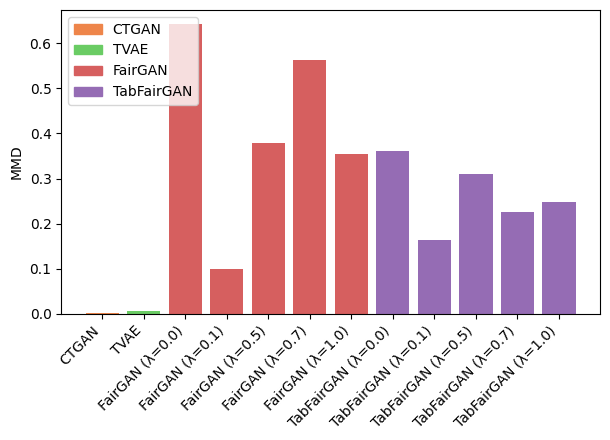

In [26]:
mmd_data = final_df["MMD"].dropna()
mmd_colors = color_by_model.copy()
mmd_colors.pop("Real")

plt.figure(figsize=fig_size)
plt.bar(mmd_data.index, mmd_data.values, color=get_colors(color_by_model, mmd_data))
plt.ylabel("MMD")
# plt.title("Statistical realism by model")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=mmd_colors[model]) for model in mmd_colors
    ],
    labels=list(mmd_colors.keys()),
    loc="upper left",
)
plt.savefig(f"{figure_folder}/stat_realism_mmd.{img_format}", dpi=300)
plt.show()

### Predictive utility (accuracy + AUC)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


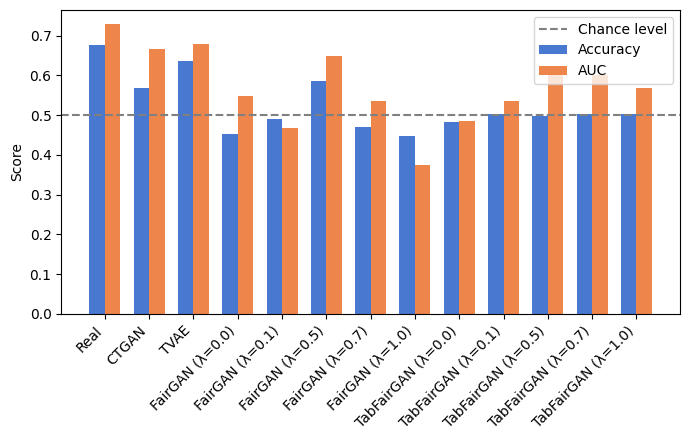

In [27]:
utility_data = final_df[["accuracy", "auc"]].dropna()
model_names = utility_data.index
x_positions = np.arange(len(model_names))
bar_width = 0.35

plt.figure(figsize=(7, 4.5))
plt.bar(
    x_positions - bar_width / 2,
    utility_data["accuracy"],
    bar_width,
    label="Accuracy",
    color=base_palette[0],
)
plt.bar(
    x_positions + bar_width / 2,
    utility_data["auc"],
    bar_width,
    label="AUC",
    color=base_palette[1],
)
plt.axhline(0.5, color="gray", linestyle="--", label="Chance level")
plt.xticks(x_positions, model_names, rotation=45, ha="right")
plt.ylabel("Score")
# plt.title("Predictive utility by model")
plt.legend()
plt.tight_layout()
plt.savefig(f"{figure_folder}/predictive_utility.{img_format}", dpi=300)
plt.show()

### Trade-off across λ (FairGAN and TabFairGAN)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


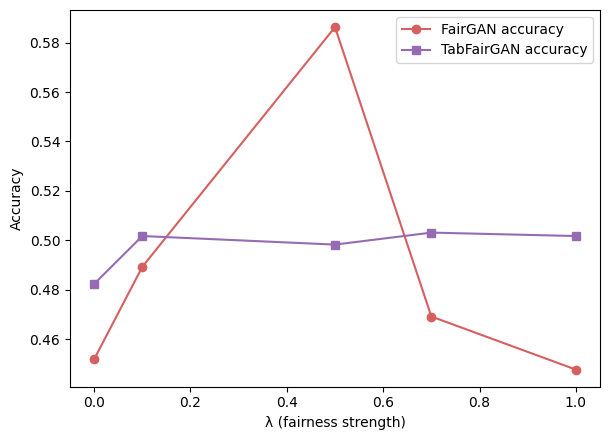

In [28]:
fairgan_labels = [x for x in final_df.index if "FairGAN" in x and "Tab" not in x]
fairgan_lambdas = [0.0, 0.1, 0.5, 0.7, 1.0]

tabfairgan_labels = [x for x in final_df.index if "TabFairGAN" in x]
tabfairgan_lambdas = [0.0, 0.1, 0.5, 0.7, 1.0]

fairgan_accuracy = final_df.loc[fairgan_labels, "accuracy"]
tabfairgan_accuracy = final_df.loc[tabfairgan_labels, "accuracy"]

fig, ax1 = plt.subplots(figsize=fig_size)
ax1.plot(
    fairgan_lambdas,
    fairgan_accuracy,
    marker="o",
    color=color_by_model["FairGAN"],
    label="FairGAN accuracy",
)
ax1.plot(
    tabfairgan_lambdas,
    tabfairgan_accuracy,
    marker="s",
    color=color_by_model["TabFairGAN"],
    label="TabFairGAN accuracy",
)
ax1.set_xlabel("λ (fairness strength)")
ax1.set_ylabel("Accuracy")
# ax1.set_title("Utility vs. λ")
ax1.legend()
plt.tight_layout()
plt.savefig(f"{figure_folder}/lambda_tradeoff.{img_format}", dpi=300)
plt.show()


## Fairness metrics

In [29]:
fairness_cols = [
    "demographic_parity",
    "disparate_impact",
    "equal_opportunity",
    "equalized_odds",
]

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


demographic_parity plot:


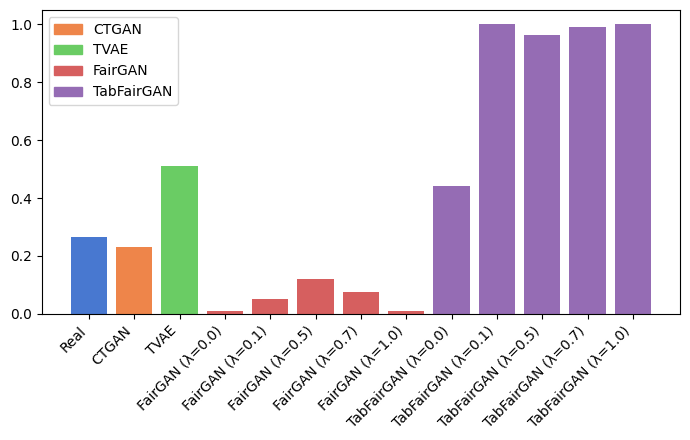

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


disparate_impact plot:


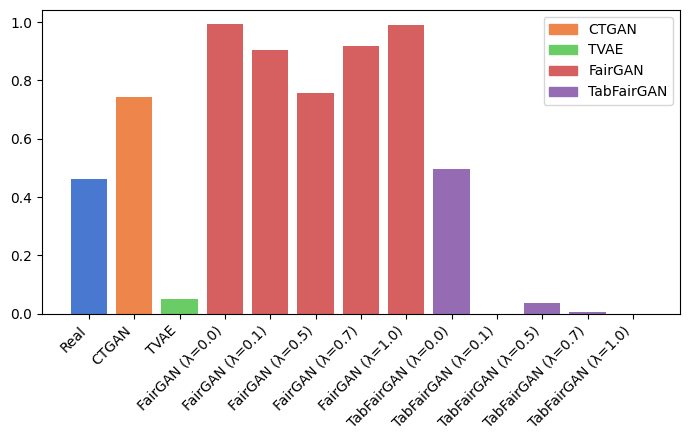

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


equal_opportunity plot:


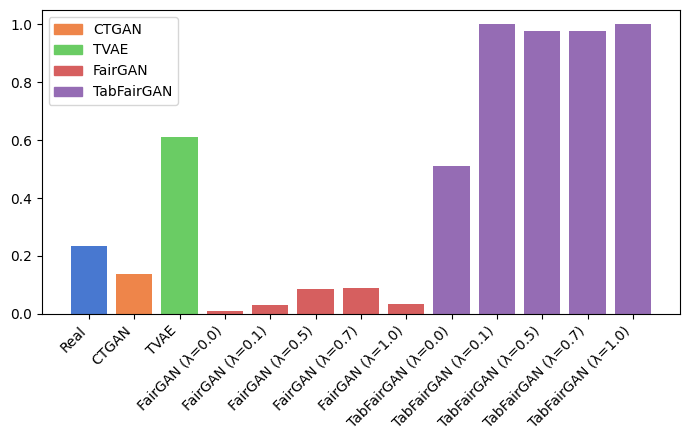

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


equalized_odds plot:


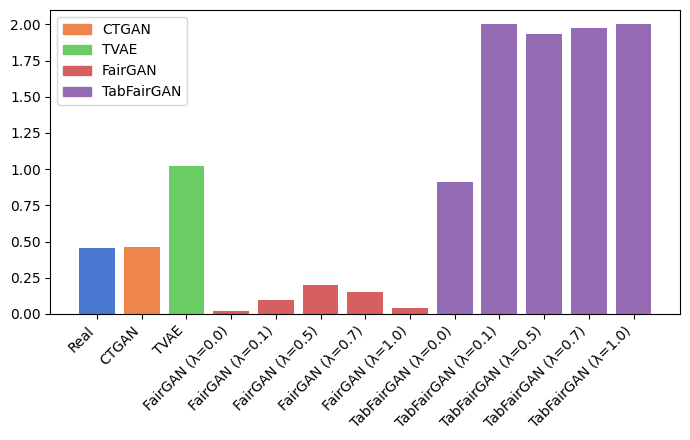

In [30]:
for metric in fairness_cols:
    plt.figure(figsize=(7, 4.5))
    plt.bar(
        final_df.index,
        final_df[metric],
        color=get_colors(color_by_model, final_df[metric]),
    )
    # plt.title(f"Fairness metric: {format_metric_names(idx)}")
    plt.xticks(rotation=45, ha="right")
    plt.legend(
        handles=[
            plt.Rectangle((0, 0), 1, 1, color=mmd_colors[model]) for model in mmd_colors
        ],
        labels=list(mmd_colors.keys()),
        loc="upper left" if metric != "disparate_impact" else "upper right",
    )
    plt.tight_layout()
    plt.savefig(f"{figure_folder}/fairness_{metric}.{img_format}", dpi=300)
    print(f"{metric} plot:")
    plt.show()

## Result tables in latex

In [31]:
table_folder = "figures/tables"

formatted_col_names = {
    "accuracy": "Accuracy",
    "auc": "AUC",
    "demographic_parity": "DP",
    "disparate_impact": "DI",
    "equal_opportunity": "Equal Opp.",
    "equalized_odds": "Equa. Odds",
    "MMD": "MMD",
}

In [32]:
def create_table(df_tbl: pd.DataFrame, table_name: str, caption: str):
    df_local = df_tbl.copy()
    df_local = df_local.dropna()
    df_local.insert(0, "Model", convert_model_names(df_local.index, format="latex"))

    df_local = df_local.rename(
        mapper=formatted_col_names,
        axis="columns",
    )
    latex_code = df_local.to_latex(
        index=False,
        na_rep="N/A",
        position="h!",
        column_format=f"l{'c' * (len(df_local.columns) - 1)}",
        float_format="%.3f",
        header=True,
        caption=caption,
        label=f"tab:results-{table_name}",
    )
    latex_code = latex_code.replace("\\begin{tabular}", "\\centering\n\\begin{tabular}")
    print(f"Table for {table_name}:\n{latex_code}\n")

    with open(f"figures/tables/results-{table_name}.tex", "w") as latex_file:
        latex_file.write(latex_code)

In [33]:
create_table(
    final_df[["MMD"]], "realism-mmd", "Statistical realism (MMD) across all models"
)
create_table(
    final_df[["accuracy", "auc"]], "utility", "Utility metrics across all models"
)
create_table(
    final_df[
        [
            "demographic_parity",
            "disparate_impact",
            "equal_opportunity",
            "equalized_odds",
        ]
    ],
    "fairness",
    "Fairness metrics across all models",
)

create_table(
    final_df,
    "all",
    "Results across all evaluated model configurations",
)

Table for realism-mmd:
\begin{table}[h!]
\caption{Statistical realism (MMD) across all models}
\label{tab:results-realism-mmd}
\centering
\begin{tabular}{lc}
\toprule
Model & MMD \\
\midrule
CTGAN & 0.003 \\
TVAE & 0.006 \\
FairGAN ($\lambda=0.0$) & 0.642 \\
FairGAN ($\lambda=0.1$) & 0.100 \\
FairGAN ($\lambda=0.5$) & 0.380 \\
FairGAN ($\lambda=0.7$) & 0.563 \\
FairGAN ($\lambda=1.0$) & 0.355 \\
TabFairGAN ($\lambda=0.0$) & 0.360 \\
TabFairGAN ($\lambda=0.1$) & 0.164 \\
TabFairGAN ($\lambda=0.5$) & 0.309 \\
TabFairGAN ($\lambda=0.7$) & 0.227 \\
TabFairGAN ($\lambda=1.0$) & 0.247 \\
\bottomrule
\end{tabular}
\end{table}


Table for utility:
\begin{table}[h!]
\caption{Utility metrics across all models}
\label{tab:results-utility}
\centering
\begin{tabular}{lcc}
\toprule
Model & Accuracy & AUC \\
\midrule
Real & 0.675 & 0.728 \\
CTGAN & 0.568 & 0.666 \\
TVAE & 0.635 & 0.679 \\
FairGAN ($\lambda=0.0$) & 0.452 & 0.548 \\
FairGAN ($\lambda=0.1$) & 0.489 & 0.468 \\
FairGAN ($\lambda=0.5$) & 0

In [34]:
print("Real:", real_train_df.groupby("sex")["is_recid"].mean().round(3).to_dict())

for name in ["TabFairGAN_0.0", "TabFairGAN_0.1", "TabFairGAN_0.5", "TabFairGAN_0.7", "TabFairGAN_1.0"]:
    rates = synthetic_datasets[name].groupby("sex")["is_recid"].mean().round(3).to_dict()
    clf = synthetic_models[name]
    c = pd.Series(clf.named_steps["classifier"].coef_[0],
                  index=clf.named_steps["preprocessor"].get_feature_names_out())
    print(f"{name}: recid rate {rates}, sex effect (M-F) {c['cat__sex_Male'] - c['cat__sex_Female']:.2f}")

Real: {'Female': 0.384, 'Male': 0.514}
TabFairGAN_0.0: recid rate {'Female': 0.305, 'Male': 0.553}, sex effect (M-F) 0.83
TabFairGAN_0.1: recid rate {'Female': 0.046, 'Male': 0.919}, sex effect (M-F) 4.91
TabFairGAN_0.5: recid rate {'Female': 0.04, 'Male': 0.895}, sex effect (M-F) 4.35
TabFairGAN_0.7: recid rate {'Female': 0.052, 'Male': 0.931}, sex effect (M-F) 5.07
TabFairGAN_1.0: recid rate {'Female': 0.062, 'Male': 0.932}, sex effect (M-F) 4.82
